<a href="https://colab.research.google.com/github/JulTob/Modelling/blob/main/GLM/GLM_2_07.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

equipo	N	m_sin	disp_sin	p0_fraude	p_evento	p_baja	m_coste
equipo_07	260107	1.1	1.1	1	1.1	0.7	1.7	1.05	0.56


In [58]:

library(tidyverse)
library(dplyr)
library(ggplot2)
library(treemapify)

# Fuente de datos del equipo 07
repositorio <- "https://raw.githubusercontent.com/JulTob/Modelling/698dad06c4228ea79319fdba27647a0c61474703/GLM/"

cartera <- read_csv(
    paste0(repositorio, "cartera.csv"),
    show_col_types = FALSE
    )

# Comprobar que los datos son válidos
stopifnot(
    nrow(cartera) > 0,
    all(c("n_siniestros", "n_asistencia", "exposicion")    %in% names(cartera)),
    all(!is.na(cartera$exposicion)),
    all(cartera$exposicion > 0)
    )

glimpse(cartera)
summary(cartera$exposicion)

class(cartera)
is.data.frame(cartera)

Rows: 3,062
Columns: 40
$ id_poliza           <dbl> 1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12, 13, 14, 15,…
$ id_agencia          <dbl> 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1,…
$ id_region           <dbl> 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1,…
$ antiguedad          <dbl> 1.082, 6.687, 5.732, 1.397, 1.968, 3.159, 3.821, 7…
$ exposicion          <dbl> 0.1082, 0.6687, 0.5732, 0.1397, 0.1968, 0.3159, 0.…
$ edad_conductor      <dbl> 33, 44, 62, 25, 66, 25, 18, 44, 49, 36, 77, 36, 39…
$ edad_tramo          <chr> "25-35", "35-65", "35-65", "18-25", "65+", "18-25"…
$ antiguedad_carnet   <dbl> 7, 13, 36, 6, 36, 7, 0, 11, 30, 7, 49, 12, 16, 17,…
$ potencia_cv         <dbl> 85, 142, 118, 76, 55, 120, 143, 64, 113, 136, 141,…
$ cilindrada          <dbl> 1417, 2423, 1831, 1278, 824, 1816, 1730, 1006, 162…
$ antiguedad_vehiculo <dbl> 6, 12, 6, 9, 10, 6, 11, 10, 19, 4, 7, 12, 19, 4, 7…
$ valor_vehiculo      <dbl> 35790, 22089, 31528, 25948, 20714, 15821, 23040, 2…
$ densidad      

   Min. 1st Qu.  Median    Mean 3rd Qu.    Max. 
 0.0100  0.2194  0.3768  0.4207  0.5934  0.9996 

[1] "spec_tbl_df" "tbl_df"      "tbl"         "data.frame"

[1] TRUE

--- Relationship Analysis ---
Maximum number of regions within a single agency: 1 
Maximum number of agencies within a single region: 5 

Each agency belongs to exactly one region, but a region can contain multiple agencies. (Region contains Agency)


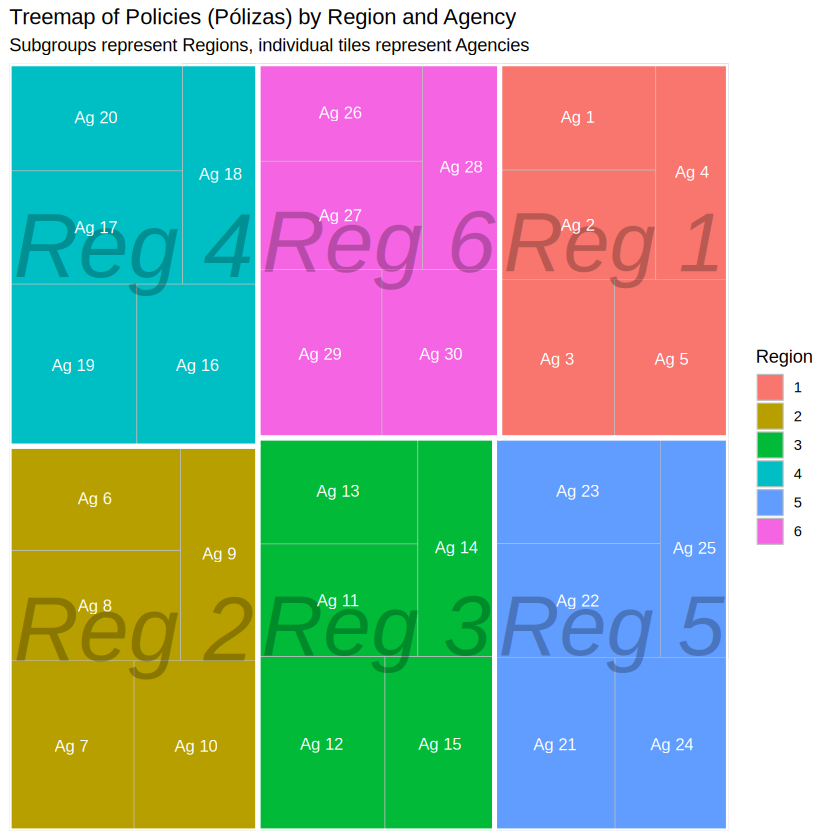

In [35]:

# 1. Analyze the relationship between agencies and regions
relationship_check <- cartera %>%
  group_by(id_agencia) %>%
  summarise(n_unique_regions = n_distinct(id_region), .groups = 'drop')

regions_per_agencia <- max(relationship_check$n_unique_regions)

relationship_check_rev <- cartera %>%
  group_by(id_region) %>%
  summarise(n_unique_agencias = n_distinct(id_agencia), .groups = 'drop')

agencias_per_region <- max(relationship_check_rev$n_unique_agencias)

cat("--- Relationship Analysis ---\n")
cat("Maximum number of regions within a single agency:", regions_per_agencia, "\n")
cat("Maximum number of agencies within a single region:", agencias_per_region, "\n\n")

if (regions_per_agencia == 1 && agencias_per_region > 1) {
  cat("Each agency belongs to exactly one region, but a region can contain multiple agencies. (Region contains Agency)\n")
} else if (agencias_per_region == 1 && regions_per_agencia > 1) {
  cat("Each region belongs to exactly one agency, but an agency can contain multiple regions. (Agency contains Region)\n")
} else if (regions_per_agencia == 1 && agencias_per_region == 1) {
  cat("There is a 1-to-1 relationship between agency and region.\n")
} else {
  cat("There is a many-to-many relationship; they do not strictly contain each other hierarchically.\n")
}

# 2. Prepare data for the Tree Plot
tree_data <- cartera %>%
  group_by(id_region, id_agencia) %>%
  summarise(n_polizas = n(), .groups = "drop") %>%
  mutate(
    region_label = paste("Reg", id_region),
    agencia_label = paste("Ag", id_agencia)
  )

# 3. Create the Tree Plot
ggplot(tree_data, aes(area = n_polizas, fill = as.factor(id_region), subgroup = region_label, label = agencia_label)) +
  geom_treemap() +
  geom_treemap_subgroup_border(colour = "white", size = 4) +
  geom_treemap_subgroup_text(place = "centre", grow = TRUE, alpha = 0.25, colour = "black", fontface = "italic") +
  geom_treemap_text(colour = "white", place = "centre", size = 10, reflow = TRUE) +
  labs(
    title = "Treemap of Policies (Pólizas) by Region and Agency",
    subtitle = "Subgroups represent Regions, individual tiles represent Agencies",
    fill = "Region"
  ) +
  theme_minimal()


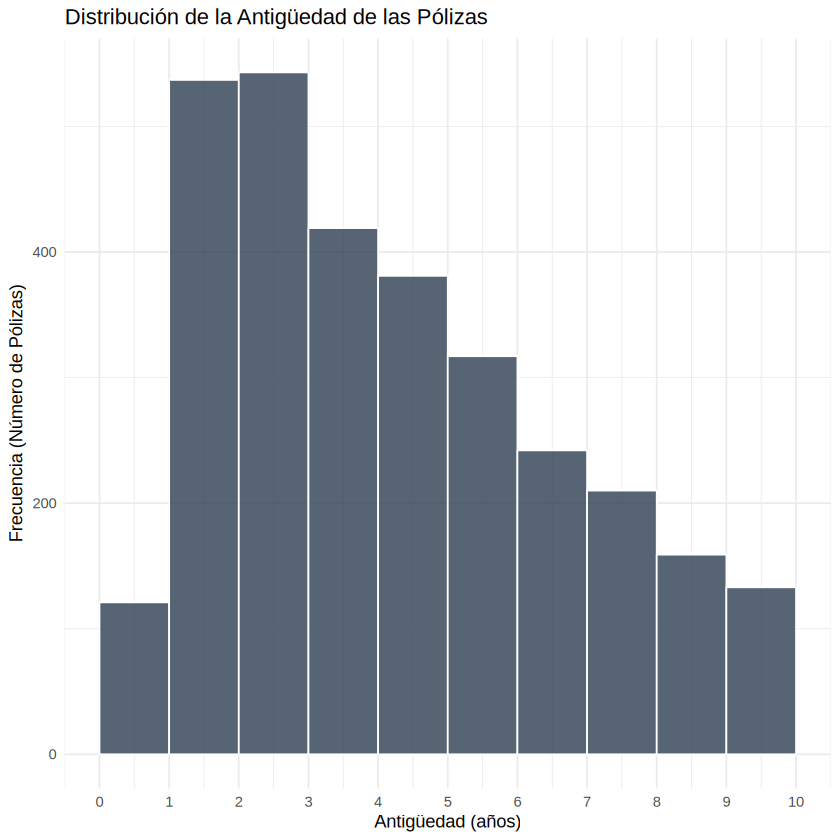

In [36]:


# Crear histograma de la variable antiguedad con cortes en enteros [0,1), [1,2), etc.
ggplot(cartera, aes(x = antiguedad)) +
  geom_histogram(binwidth = 1, boundary = 0, fill = "#2c3e50", color = "white", alpha = 0.8) +
  labs(
    title = "Distribución de la Antigüedad de las Pólizas",
    x = "Antigüedad (años)",
    y = "Frecuencia (Número de Pólizas)"
  ) +
  scale_x_continuous(breaks = 0:max(ceiling(cartera$antiguedad))) +
  theme_minimal()


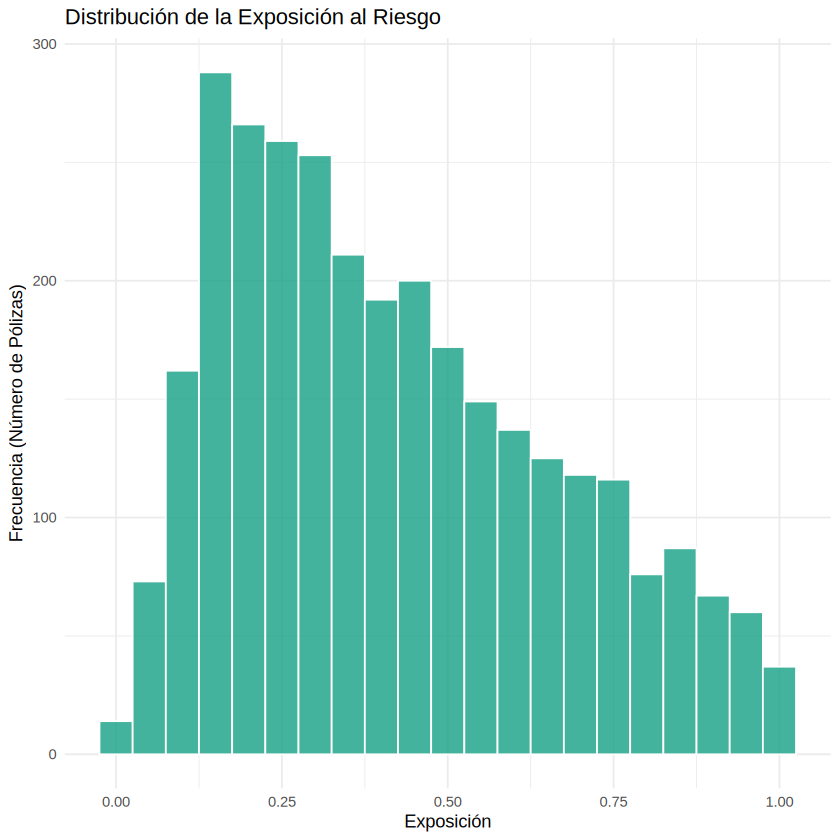

In [37]:
library(ggplot2)

# Crear histograma de la variable exposicion
ggplot(cartera, aes(x = exposicion)) +
  geom_histogram(binwidth = 0.05, fill = "#16a085", color = "white", alpha = 0.8) +
  labs(
    title = "Distribución de la Exposición al Riesgo",
    x = "Exposición",
    y = "Frecuencia (Número de Pólizas)"
  ) +
  theme_minimal()


In [38]:
library(dplyr)

# Verificar la consistencia de los tramos de edad respecto a la edad numérica
analisis_edad <- cartera %>%
  group_by(edad_tramo) %>%
  summarise(
    n_registros = n(),
    edad_min = min(edad_conductor, na.rm = TRUE),
    edad_max = max(edad_conductor, na.rm = TRUE),
    .groups = 'drop'
  ) %>%
  arrange(edad_min)

print("Análisis de rangos por tramo:")
print(analisis_edad)


[1] "Análisis de rangos por tramo:"
# A tibble: 4 × 4
  edad_tramo n_registros edad_min edad_max
  <chr>            <int>    <dbl>    <dbl>
1 18-25              296       18       25
2 25-35              520       26       35
3 35-65             1964       36       65
4 65+                282       66       88


In [39]:
library(dplyr)

# Crear la tabla comparativa de forma directa y robusta
resultado_final <- data.frame(
  Grupo_Edad = c("18-25", "25-35", "35-65", "65+"),
  Conteo_Edad_Tramo = c(
    sum(cartera$edad_tramo == "18-25", na.rm = TRUE),
    sum(cartera$edad_tramo == "25-35", na.rm = TRUE),
    sum(cartera$edad_tramo == "35-65", na.rm = TRUE),
    sum(cartera$edad_tramo == "65+", na.rm = TRUE)
  ),
  Conteo_Edad_Conductor = c(
    sum(cartera$edad_conductor >= 18 & cartera$edad_conductor <= 25, na.rm = TRUE),
    sum(cartera$edad_conductor >= 26 & cartera$edad_conductor <= 35, na.rm = TRUE),
    sum(cartera$edad_conductor >= 36 & cartera$edad_conductor <= 65, na.rm = TRUE),
    sum(cartera$edad_conductor >= 66, na.rm = TRUE)
  )
)

print("Tabla comparativa de conteos:")
print(resultado_final)

[1] "Tabla comparativa de conteos:"
  Grupo_Edad Conteo_Edad_Tramo Conteo_Edad_Conductor
1      18-25               296                   296
2      25-35               520                   520
3      35-65              1964                  1964
4        65+               282                   282


In [40]:
# Comprobación de seguridad mediante filtros:
# Buscar si existen registros donde la edad numérica no cuadre con su tramo correspondiente
inconsistencias <- cartera %>%
  filter(
    (edad_tramo == "18-25" & (edad_conductor < 18 | edad_conductor > 25)) |
    (edad_tramo == "25-35" & (edad_conductor < 26 | edad_conductor > 35)) |
    (edad_tramo == "35-65" & (edad_conductor < 36 | edad_conductor > 65)) |
    (edad_tramo == "65+"   & (edad_conductor < 66))
  ) %>%
  select(id_poliza, edad_conductor, edad_tramo)

cat("Número de registros inconsistentes encontrados:", nrow(inconsistencias), "\n")
if(nrow(inconsistencias) > 0) {
  print(inconsistencias)
} else {
  cat("¡Confirmado! Todos los registros cumplen perfectamente la regla de correspondencia.\n")
}


Número de registros inconsistentes encontrados: 0 
¡Confirmado! Todos los registros cumplen perfectamente la regla de correspondencia.


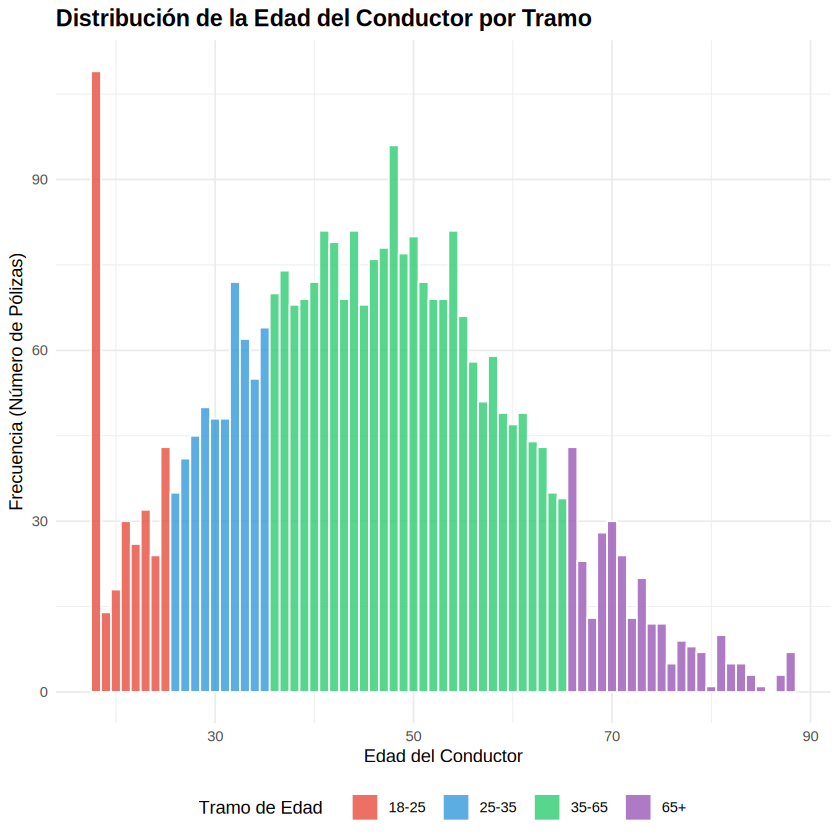

In [41]:
library(ggplot2)
library(dplyr)

# Crear un histograma de la edad del conductor coloreando por tramo de edad
ggplot(cartera, aes(x = edad_conductor, fill = edad_tramo)) +
  geom_histogram(binwidth = 1, color = "white", alpha = 0.8, position = "identity") +
  scale_fill_manual(
    values = c("18-25" = "#e74c3c", "25-35" = "#3498db", "35-65" = "#2ecc71", "65+" = "#9b59b6"),
    name = "Tramo de Edad"
  ) +
  labs(
    title = "Distribución de la Edad del Conductor por Tramo",
    x = "Edad del Conductor",
    y = "Frecuencia (Número de Pólizas)"
  ) +
  theme_minimal() +
  theme(
    legend.position = "bottom",
    plot.title = element_text(face = "bold", size = 14)
  )

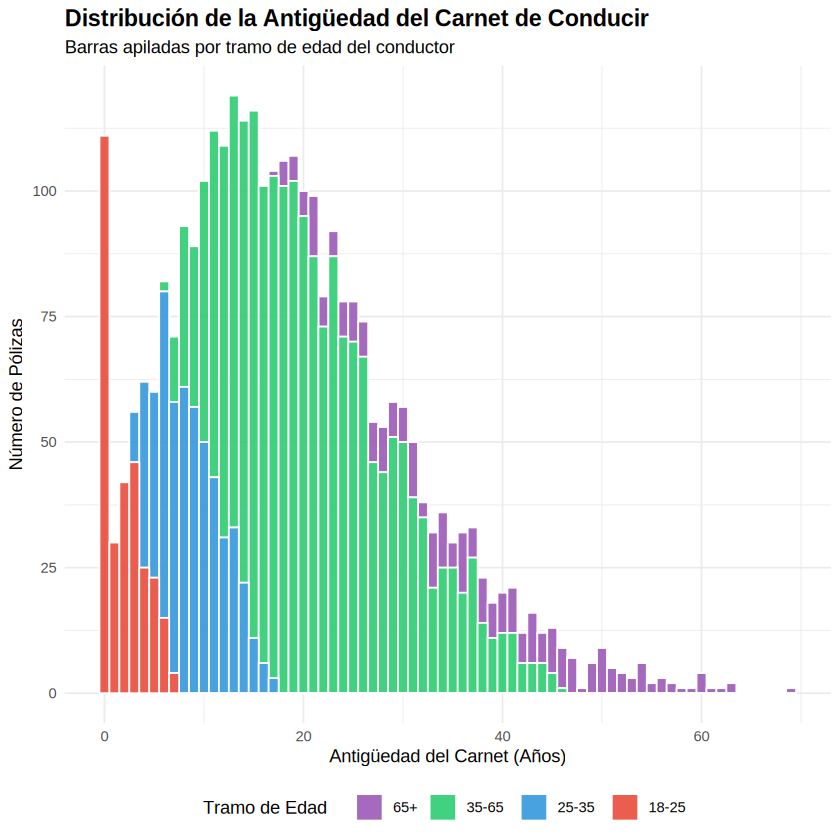

In [42]:
library(ggplot2)
library(dplyr)

# Asegurar que edad_tramo sea un factor con el orden correcto para el apilado
cartera_plot <- cartera %>%
  mutate(edad_tramo = factor(edad_tramo, levels = c("65+", "35-65", "25-35", "18-25")))

# Crear el histograma apilado de la antigüedad de carnet
ggplot(cartera_plot, aes(x = antiguedad_carnet, fill = edad_tramo)) +
  geom_histogram(binwidth = 1, color = "white", position = "stack", alpha = 0.9) +
  scale_fill_manual(
    values = c(
      "18-25" = "#e74c3c",  # Rojo abajo
      "25-35" = "#3498db",  # Azul encima
      "35-65" = "#2ecc71",  # Verde encima
      "65+"   = "#9b59b6"   # Morado arriba del todo
    ),
    breaks = c("65+", "35-65", "25-35", "18-25"), # Controla el orden en la leyenda
    name = "Tramo de Edad"
  ) +
  labs(
    title = "Distribución de la Antigüedad del Carnet de Conducir",
    subtitle = "Barras apiladas por tramo de edad del conductor",
    x = "Antigüedad del Carnet (Años)",
    y = "Número de Pólizas"
  ) +
  theme_minimal() +
  theme(
    legend.position = "bottom",
    plot.title = element_text(face = "bold", size = 14)
  )

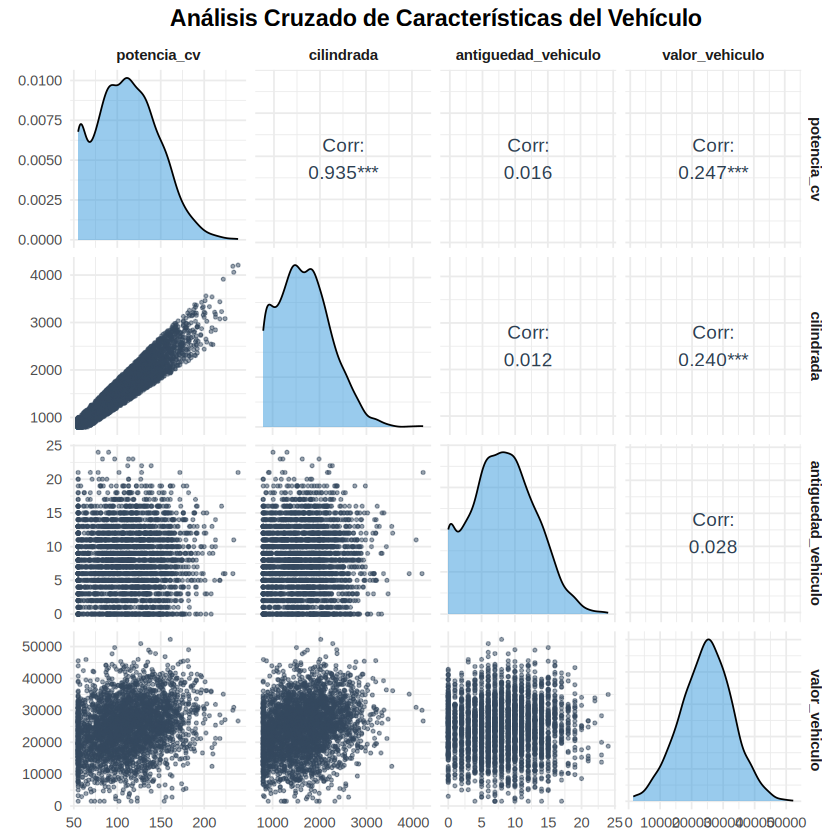

In [43]:
if (!requireNamespace("GGally", quietly = TRUE)) {
  install.packages("GGally", repos = "https://cloud.r-project.org")
}

library(GGally)
library(ggplot2)
library(dplyr)

# Seleccionar las variables de interés
variables_cruzadas <- cartera %>%
  select(potencia_cv, cilindrada, antiguedad_vehiculo, valor_vehiculo)

# Generar el gráfico de matriz cruzada (ggpairs)
ggpairs(
  variables_cruzadas,
  title = "Análisis Cruzado de Características del Vehículo",
  lower = list(continuous = wrap("points", alpha = 0.5, size = 0.8, color = "#34495e")),
  diag = list(continuous = wrap("densityDiag", fill = "#3498db", alpha = 0.5)),
  upper = list(continuous = wrap("cor", size = 4, color = "#2c3e50"))
) +
  theme_minimal() +
  theme(
    plot.title = element_text(face = "bold", size = 14, hjust = 0.5),
    strip.text = element_text(face = "bold", size = 9)
  )

Installing package into ‘/usr/local/lib/R/site-library’
(as ‘lib’ is unspecified)


Attaching package: ‘gridExtra’


The following object is masked from ‘package:dplyr’:

    combine




Variables encontradas en el dataset: densidad, km_anuales, uso, combustible 

    densidad         km_anuales           uso          combustible  
 Min.   :    7.0   Min.   : 1863   Length   :3062   Length   :3062  
 1st Qu.:  141.0   1st Qu.: 8523   N.unique :   2   N.unique :   2  
 Median :  302.5   Median :11874   N.blank  :   0   N.blank  :   0  
 Mean   :  542.9   Mean   :13523   Min.nchar:   9   Min.nchar:   6  
 3rd Qu.:  633.5   3rd Qu.:16743   Max.nchar:  10   Max.nchar:   8  
 Max.   :15934.0   Max.   :60000                                    


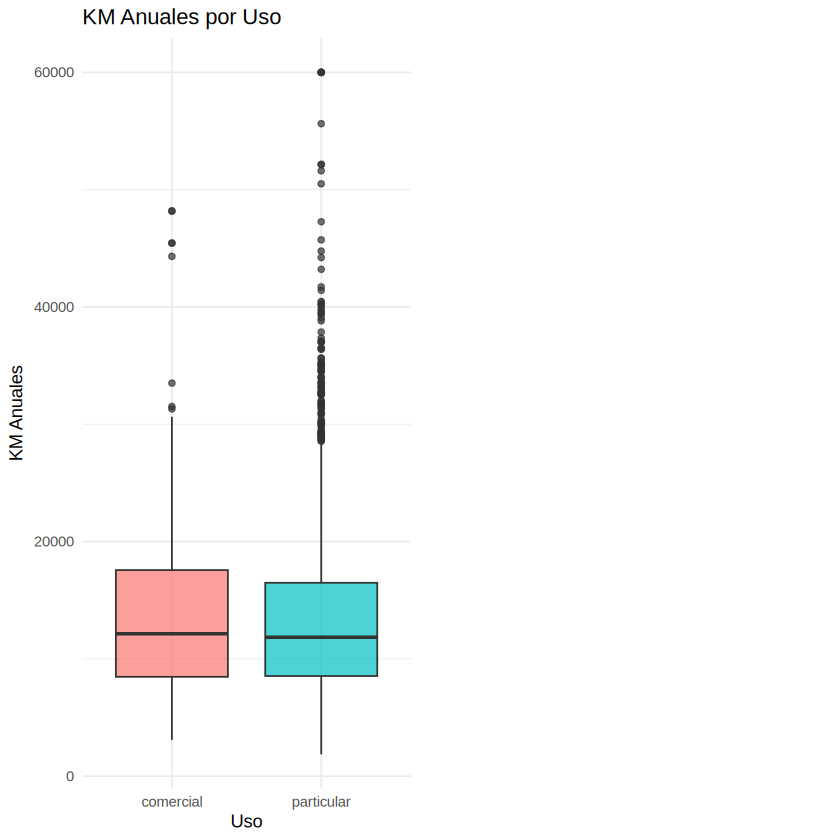

In [45]:
if (!requireNamespace("gridExtra", quietly = TRUE)) {
  install.packages("gridExtra", repos = "https://cloud.r-project.org")
}

library(ggplot2)
library(dplyr)
library(gridExtra)

# 1. Inspeccionar nombres exactos de estas columnas en el dataset
columnas_interes <- c("densidad", "zona", "km_anuales", "uso", "tipo", "combustible", "color")
columnas_presentes <- intersect(columnas_interes, names(cartera))

cat("Variables encontradas en el dataset:", paste(columnas_presentes, collapse = ", "), "\n\n")

# 2. Resumen rápido de las variables categóricas principales
cartera %>%
  select(all_of(columnas_presentes)) %>%
  summary() %>%
  print()

# 3. Visualizaciones cruzadas de interés
plots <- list()

# Gráfico A: Distribución de Kilómetros Anuales según el Uso del Vehículo
if("km_anuales" %in% names(cartera) & "uso" %in% names(cartera)) {
  plots[[1]] <- ggplot(cartera, aes(x = uso, y = km_anuales, fill = uso)) +
    geom_boxplot(alpha = 0.7, show.legend = FALSE) +
    labs(title = "KM Anuales por Uso", x = "Uso", y = "KM Anuales") +
    theme_minimal()
}

# Gráfico B: Frecuencia de Tipo de Vehículo según Combustible
if("tipo" %in% names(cartera) & "combustible" %in% names(cartera)) {
  plots[[2]] <- ggplot(cartera, aes(x = tipo, fill = combustible)) +
    geom_bar(position = "dodge") +
    labs(title = "Tipo de Vehículo por Combustible", x = "Tipo", y = "Cantidad") +
    theme_minimal() +
    theme(axis.text.x = element_text(angle = 45, hjust = 1))
}

# Gráfico C: Relación entre Zona y Densidad
if("zona" %in% names(cartera) & "densidad" %in% names(cartera)) {
  plots[[3]] <- ggplot(cartera, aes(x = as.factor(zona), y = densidad, fill = as.factor(zona))) +
    geom_boxplot(alpha = 0.7, show.legend = FALSE) +
    labs(title = "Densidad por Zona", x = "Zona", y = "Densidad") +
    theme_minimal()
}

# Gráfico D: Distribución del Color de los vehículos
if("color" %in% names(cartera)) {
  plots[[4]] <- ggplot(cartera, aes(x = color, fill = color)) +
    geom_bar(show.legend = FALSE) +
    labs(title = "Distribución por Color", x = "Color del Vehículo", y = "Cantidad") +
    theme_minimal() +
    theme(axis.text.x = element_text(angle = 45, hjust = 1))
}

# Mostrar los gráficos juntos de forma limpia
valid_plots <- plots[!sapply(plots, is.null)]
if(length(valid_plots) > 0) {
  grid.arrange(grobs = valid_plots, ncol = 2)
}

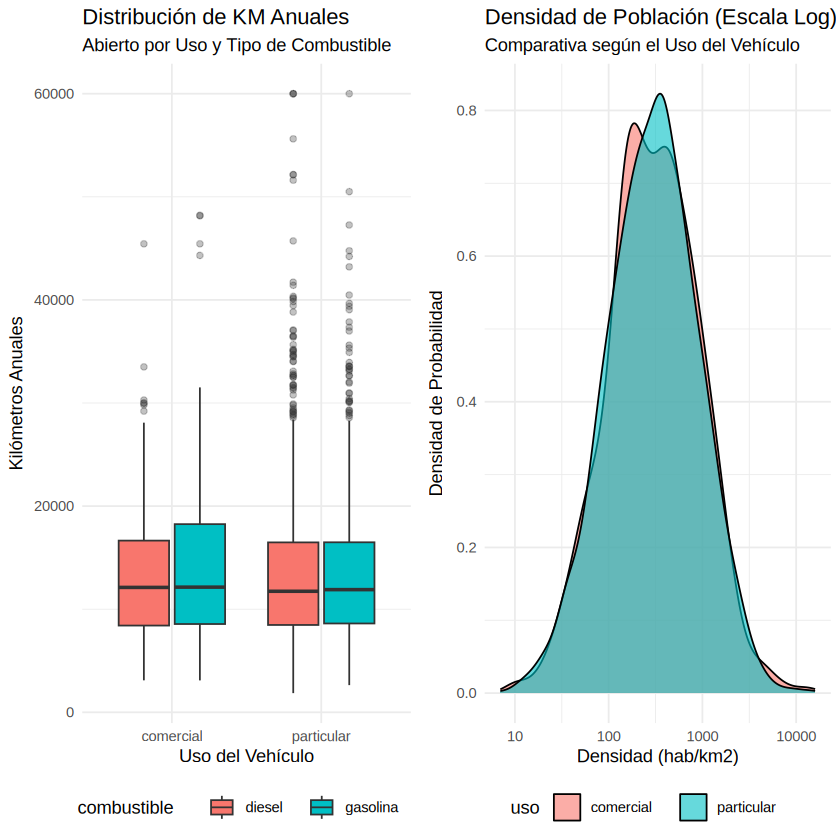

In [46]:
library(ggplot2)
library(gridExtra)
library(dplyr)

# Como 'zona', 'tipo' y 'color' no existen en la tabla 'cartera',
# maximizamos el análisis con las variables reales disponibles: densidad, km_anuales, uso y combustible.

# Gráfico 1: Relación entre Kilómetros Anuales, Uso y Combustible
p1 <- ggplot(cartera, aes(x = uso, y = km_anuales, fill = combustible)) +
  geom_boxplot(outlier.alpha = 0.3) +
  labs(
    title = "Distribución de KM Anuales",
    subtitle = "Abierto por Uso y Tipo de Combustible",
    x = "Uso del Vehículo",
    y = "Kilómetros Anuales"
  ) +
  theme_minimal() +
  theme(legend.position = "bottom")

# Gráfico 2: Distribución de Densidad de Población por Uso
p2 <- ggplot(cartera, aes(x = densidad, fill = uso)) +
  geom_density(alpha = 0.6) +
  scale_x_log10() + # Escala logarítmica dado que la densidad tiene un sesgo extremo
  labs(
    title = "Densidad de Población (Escala Log)",
    subtitle = "Comparativa según el Uso del Vehículo",
    x = "Densidad (hab/km2)",
    y = "Densidad de Probabilidad"
  ) +
  theme_minimal() +
  theme(legend.position = "bottom")

# Mostrar ambos gráficos en pantalla
grid.arrange(p1, p2, ncol = 2)

-----

# Eventos Esperados

- $y[i]$: Siniestros reales, ocurrentes en el cliente $i$
- $exp[i]$: Exposición del cliente i. Tiempo de observación. Transformamos para expresar en años.
- $λ[i]$: Tasa de siniestros. A qué ritmo esperamos que ocurran los siniestros para ese perfil de póliza.
$$
λ[i] = y[i] * exp[i]
$$

- $Ŷ[i]$: Siniestros esperados durante su exposición.
$$
Ŷ[i] = exp[i] · λ[i]
$$



In [53]:
# Crear la subtabla de datos
data <- cartera %>%
  mutate(exposicion = exposicion * 10) %>%
  select(id_poliza, exposicion, n_siniestros)

# Mostrar las primeras filas para verificar el resultado
head(subtabla_siniestros)

id_poliza,exposicion,n_siniestros
<dbl>,<dbl>,<dbl>
1,1.082,1
2,6.687,0
3,5.732,4
4,1.397,0
5,1.968,0
6,3.159,1


In [66]:
tasa <- function(
        eventos,
        exposicion
        ) {
    #-- Control de errores: una exposición de 0 daría infinito
    stopifnot(
        length(eventos) == length(exposicion),
        all(!is.na(exposicion)),
        all(exposicion > 0)
        )
    eventos / exposicion
}

data <- cartera %>%
    mutate(
        tasa_siniestros = tasa(n_siniestros, exposicion),
        tasa_asistencia = tasa(n_asistencia, exposicion)
        )

summary(data)

   id_poliza        id_agencia      id_region       antiguedad   
 Min.   :   1.0   Min.   : 1.00   Min.   :1.000   Min.   :0.100  
 1st Qu.: 766.2   1st Qu.: 8.00   1st Qu.:2.000   1st Qu.:2.194  
 Median :1531.5   Median :16.00   Median :4.000   Median :3.768  
 Mean   :1531.5   Mean   :15.57   Mean   :3.514   Mean   :4.207  
 3rd Qu.:2296.8   3rd Qu.:23.00   3rd Qu.:5.000   3rd Qu.:5.934  
 Max.   :3062.0   Max.   :30.00   Max.   :6.000   Max.   :9.996  
                                                                 
   exposicion     edad_conductor      edad_tramo   antiguedad_carnet
 Min.   :0.0100   Min.   :18.00   Length   :3062   Min.   : 0.00    
 1st Qu.:0.2194   1st Qu.:35.00   N.unique :   4   1st Qu.:10.00    
 Median :0.3768   Median :45.00   N.blank  :   0   Median :17.00    
 Mean   :0.4207   Mean   :45.37   Min.nchar:   3   Mean   :18.52    
 3rd Qu.:0.5934   3rd Qu.:55.00   Max.nchar:   5   3rd Qu.:25.00    
 Max.   :0.9996   Max.   :88.00                    Max.   

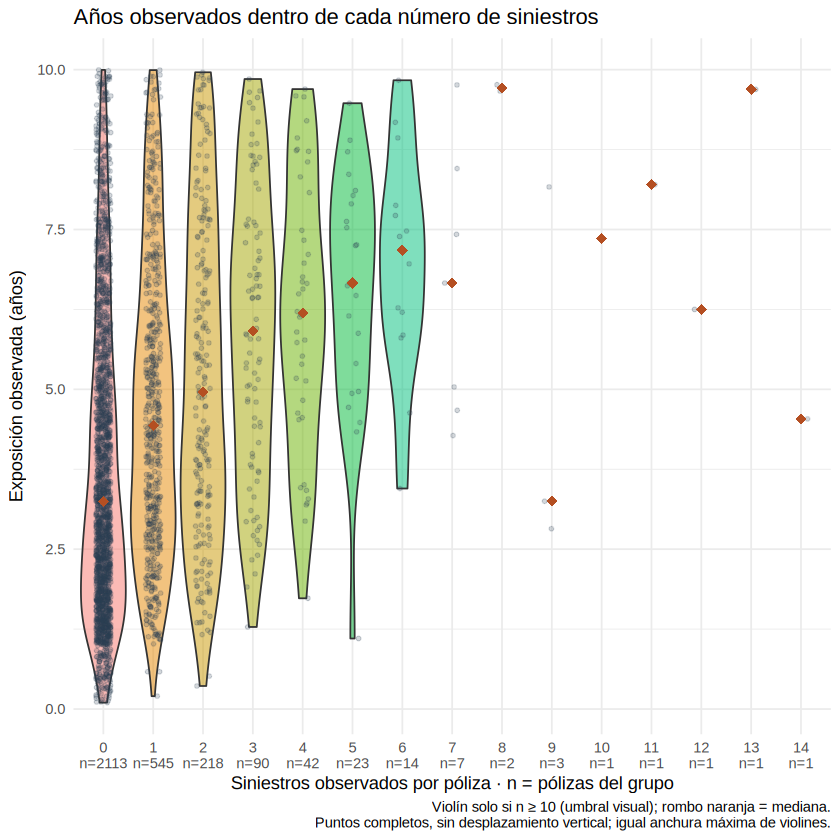

In [60]:
library(ggplot2)
library(dplyr)

# subtabla_siniestros$exposicion ya está en años.
datos_violin <- subtabla_siniestros |>
  add_count(n_siniestros, name = "n_grupo") |>
  mutate(grupo = factor(n_siniestros))

etiquetas <- datos_violin |> distinct(grupo, n_grupo)

ggplot(datos_violin, aes(grupo, exposicion, fill = grupo)) +
  geom_violin(
    data = filter(datos_violin, n_grupo >= 10),
    trim = TRUE,
    scale = "width",
    alpha = 0.5,
    show.legend = FALSE
  ) +
  geom_point(
    position = position_jitter(
      width = 0.15, height = 0, seed = 7
    ),
    alpha = 0.2,
    size = 1,
    colour = "#2c3e50",
    show.legend = FALSE
  ) +
  stat_summary(
    fun = median,
    geom = "point",
    shape = 18,
    size = 2.8,
    colour = "#b44f22",
    show.legend = FALSE
  ) +
  scale_x_discrete(labels = setNames(
    paste0(etiquetas$grupo, "\nn=", etiquetas$n_grupo),
    as.character(etiquetas$grupo)
  )) +
  labs(
    title = "Años observados dentro de cada número de siniestros",
    x = "Siniestros observados por póliza · n = pólizas del grupo",
    y = "Exposición observada (años)",
    caption = paste(
      "Violín solo si n ≥ 10 (umbral visual); rombo naranja = mediana.",
      "Puntos completos, sin desplazamiento vertical; igual anchura máxima de violines.",
      sep = "\n"
    )
  ) +
  theme_minimal()